# 03 - External Dataset Preparation

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** A model can get a very high score on its own test set and still fail on new data. To check how our model works in the real world, we test it on a second dataset that was collected by different people at a different time: the [Web Page Phishing Detection Dataset](https://www.kaggle.com/datasets/shashwatwork/web-page-phishing-detection-dataset) (Hannousse & Yahiouche, 2021).

In this notebook, we clean this dataset, make sure it does not share any URLs with PhiUSIIL, and create the same URL features we made in `02_preprocessing.ipynb`. The result is used as the external test set in Experiment 2.

**Input:** `data/dataset_phishing.csv`, `data/PhiUSIIL_Phishing_URL_Dataset.csv`

**Output:** `data/processed/external_test.csv`, `data/processed/external_urls.csv`

## Setup

We load the libraries, our feature functions from `src/features.py`, and keep all settings in one place.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path("..").resolve()))
from src.features import build_url_features

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

EXTERNAL_PATH = Path("../data/dataset_phishing.csv")
PHIUSIIL_PATH = Path("../data/PhiUSIIL_Phishing_URL_Dataset.csv")
PROCESSED_DIR = Path("../data/processed")
RESULTS_DIR = Path("../results")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

TARGET = "label"
LABEL_NAMES = {0: "Legitimate", 1: "Phishing"}
CLASS_PALETTE = {"Legitimate": "#4C72B0", "Phishing": "#C44E52"}

In [2]:
ext = pd.read_csv(EXTERNAL_PATH)
initial_shape = ext.shape
print(f"Loaded external dataset: {initial_shape[0]:,} rows | {initial_shape[1]} columns")

Loaded external dataset: 11,430 rows | 89 columns


## 1. Dataset Overview

This dataset has a `url` column, 87 features and a `status` column (the label). Its 87 features are different from the PhiUSIIL features, so a model trained on PhiUSIIL cannot use them. Because of this, we only keep the `url` and `status` columns, and we create our own features from the URL.

In [3]:
ext[["url", "status"]].head()

,url,status
0,http://www.crestonwood.com/router.php,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,phishing
2,https://support-appleld.com.secureupdate.duila...,phishing
3,http://rgipt.ac.in,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,legitimate


In [4]:
print(f"Missing values: {ext.isnull().sum().sum()}")
print(f"Label values: {ext['status'].unique().tolist()}")

Missing values: 0
Label values: ['legitimate', 'phishing']


## 2. Remove Duplicate URLs

Just like in PhiUSIIL, we check whether any URL appears more than once, and whether a repeated URL has two different labels. We then keep only the first copy of each URL.

In [5]:
dup_mask = ext["url"].duplicated(keep=False)
conflicts = ext[dup_mask].groupby("url")["status"].nunique().gt(1).sum()

print(f"Duplicate URLs: {ext['url'].duplicated().sum()}")
print(f"Duplicated URLs with different labels: {conflicts}")

ext = ext.drop_duplicates(subset="url", keep="first").reset_index(drop=True)
print(f"Rows remaining: {len(ext):,}")

Duplicate URLs: 1
Duplicated URLs with different labels: 0
Rows remaining: 11,429


## 3. Change the Label

The label in this dataset is text: `legitimate` or `phishing`. We turn it into numbers in the same way as PhiUSIIL, so that **1 = Phishing** and **0 = Legitimate**.

In [6]:
ext[TARGET] = ext["status"].map({"legitimate": 0, "phishing": 1})

print(f"Labels that could not be converted: {ext[TARGET].isnull().sum()}")
ext[TARGET].map(LABEL_NAMES).value_counts()

Labels that could not be converted: 0


label
Legitimate    5715
Phishing      5714
Name: count, dtype: int64

## 4. Remove URLs Shared with PhiUSIIL

If a URL is in both datasets, the model has already seen it during training, and the external test would not be fair. We compare the URLs of both datasets and remove every shared URL from this dataset.

Before comparing, we make the URLs consistent: we remove extra spaces, make all letters lowercase and remove a `/` at the end. Without this step, `https://example.com/` and `https://Example.com` would look like two different URLs.

In [7]:
def normalize_url(url):
    return str(url).strip().lower().rstrip("/")


phiusiil_urls = set(pd.read_csv(PHIUSIIL_PATH, usecols=["URL"])["URL"].map(normalize_url))
is_shared = ext["url"].map(normalize_url).isin(phiusiil_urls)

print(f"URLs also found in PhiUSIIL: {is_shared.sum()}")
print(ext.loc[is_shared, TARGET].map(LABEL_NAMES).value_counts().to_string())

ext = ext[~is_shared].reset_index(drop=True)
print(f"\nRows remaining: {len(ext):,}")

URLs also found in PhiUSIIL: 174
label
Legitimate    124
Phishing       50

Rows remaining: 11,255


## 5. Class Distribution

After cleaning, we check that the dataset is still balanced.

In [8]:
class_counts = ext[TARGET].map(LABEL_NAMES).value_counts()
class_pct = (class_counts / len(ext) * 100).round(2)
pd.DataFrame({"Count": class_counts, "Percentage (%)": class_pct})

,Count,Percentage (%)
label,,
Phishing,5664,50.32
Legitimate,5591,49.68


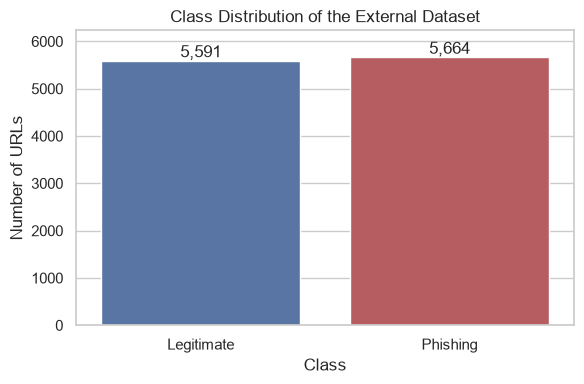

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
class_labels = ext[TARGET].map(LABEL_NAMES)
sns.countplot(x=class_labels, hue=class_labels, order=["Legitimate", "Phishing"], palette=CLASS_PALETTE, legend=False, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")

ax.margins(y=0.1)
ax.set_title("Class Distribution of the External Dataset")
ax.set_xlabel("Class")
ax.set_ylabel("Number of URLs")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "external_class_distribution.png", dpi=300)
plt.show()

### Findings: Data Cleaning

- The dataset has 11,430 URLs and no missing values.
- Only 1 URL appeared twice, and both copies had the same label. We removed the second copy.
- **174 URLs were also in PhiUSIIL** (124 legitimate and 50 phishing). We removed them, so the external test only contains URLs the model has never seen.
- After cleaning, there are **11,255 URLs**: 5,664 phishing (50.3%) and 5,591 legitimate (49.7%). The dataset is still balanced.